# LIMPIEZA DE DATOS — Actualización de la Caracterización ASP Bogotá

**-Daniela Sofía López Rivas**


**-Stefany Pulido Valero**


**-Lezly Juliana Nossa López**

# El problema

La Secretaría Distrital de la Mujer de Bogotá realizó una **actualización de la caracterización** de personas que realizan actividades sexuales pagadas (ASP) en la ciudad (formulario ARD 632, trabajo de campo de SEI). La base contiene **3.004 personas** y más de 1.000 variables.

**Pregunta que orienta el análisis:** ¿qué factores sociodemográficos explican las brechas en la cobertura y el acceso a servicios de salud dentro de esta población? (alineado con ODS 5 — Igualdad de Género, y ODS 10 — Reducción de las Desigualdades)

Antes de poder responder esa pregunta, el dataset debe pasar por un proceso de limpieza.

# El set de datos

Archivo: `asp_2022_variables_renombradas.csv`

Contiene **51 columnas** seleccionadas del Excel original (hoja *Microdatos*, ~1.016 columnas) y renombradas con nombres legibles. Los valores siguen **codificados con números** (1, 2, 99…); sus etiquetas salen de la hoja *Valores* del mismo Excel. Se agrupan en:

- **Identificación/control**: `id_persona`, `localidad`, `resultado_encuesta`, `factor_expansion`
- **Sociodemográficas**: `edad`, `sexo_nacimiento`, `orientacion_sexual`, `identidad_genero`, `estado_civil`, `autoreconocimiento_etnico`, `pais_nacimiento`, `vive_permanente_bogota`, `tiempo_viviendo_bogota`, `victima_conflicto_armado`
- **Vivienda, hogar y economía**: `tipo_vivienda`, `estrato`, `tenencia_vivienda`, `personas_hogar`, `dependientes_economicos`, `autopercepcion_nivel_economico`, `ingresos_suficientes_gastos`
- **Educación**: `sabe_leer_escribir`, `nivel_educativo`
- **Actividad (ASP)**: `actividad_principal`, `horas_semana_asp`, `edad_inicio_asp`, `paga_intermediario_tercero`, `satisfaccion_actividad`, `deseo_dejar_actividad`
- **Salud (variable de interés)**: `afiliado_seg_social_salud`, `regimen_salud`, `afiliado_pensiones`, `atencion_medica_ult_anio`, `percepcion_estado_salud`, `lugar_busqueda_tratamiento`, `no_realiza_chequeos_preventivos`, `barrera_*` (4), `prueba_vih`, `vacuna_vph`, `citologia_ultimo_anio`
- **Violencias y discriminación**: `discriminacion_general`, `discriminacion_personal_salud`, `amenazas_recibidas`, `amenaza_personal_salud`, `forzada_relaciones_sexuales`, `forzada_por_personal_salud`, `denuncio_hecho`, `violencia_fuerza_publica`

**Particularidad clave de esta encuesta:** muchas preguntas tienen *lógica de salto* (ej. `regimen_salud` solo se preguntó a quien respondió "Sí" en `afiliado_seg_social_salud`). Esas celdas vienen como `"No Aplica"`, que **no es lo mismo** que un dato faltante real (el código `99` = "No sabe/No responde").

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
datos = pd.read_csv('asp_2022_variables_renombradas.csv')

In [3]:
print("El tamaño del dataset es: ", datos.shape)
datos.head(10)

El tamaño del dataset es:  (3004, 51)


,id_persona,factor_expansion,localidad,resultado_encuesta,edad,sexo_nacimiento,orientacion_sexual,identidad_genero,estado_civil,autoreconocimiento_etnico,...,vacuna_vph,citologia_ultimo_anio,discriminacion_general,discriminacion_personal_salud,amenazas_recibidas,amenaza_personal_salud,forzada_relaciones_sexuales,forzada_por_personal_salud,denuncio_hecho,violencia_fuerza_publica
0,1501001,1.428571,ANTONIO NARIÑO,1,19,2,3,1,7,7,...,1,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
1,1501002,1.428571,ANTONIO NARIÑO,1,26,1,7,1,7,7,...,No Aplica,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
2,1501003,1.428571,ANTONIO NARIÑO,1,21,2,7,1,7,7,...,2,1,2,No Aplica,1,2,1,2,2,1
3,1501004,1.428571,ANTONIO NARIÑO,1,20,2,7,1,7,7,...,1,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
4,1501005,1.428571,ANTONIO NARIÑO,1,20,2,7,1,7,7,...,2,2,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
5,1501006,1.428571,ANTONIO NARIÑO,1,48,2,7,1,7,7,...,2,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
6,1501007,1.428571,ANTONIO NARIÑO,1,46,2,7,1,7,7,...,2,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
7,1502001,1.166667,ANTONIO NARIÑO,1,23,2,1,1,1,7,...,1,1,2,No Aplica,2,No Aplica,0,No Aplica,No Aplica,2
8,1502002,1.458333,ANTONIO NARIÑO,1,18,2,7,1,7,7,...,1,2,1,2,2,No Aplica,0,No Aplica,No Aplica,2
9,1502003,1.458333,ANTONIO NARIÑO,1,24,2,7,1,7,7,...,2,2,1,2,2,No Aplica,0,No Aplica,No Aplica,2


In [4]:
datos.columns

Index(['id_persona', 'factor_expansion', 'localidad', 'resultado_encuesta',
       'edad', 'sexo_nacimiento', 'orientacion_sexual', 'identidad_genero',
       'estado_civil', 'autoreconocimiento_etnico', 'pais_nacimiento',
       'vive_permanente_bogota', 'tiempo_viviendo_bogota',
       'victima_conflicto_armado', 'tipo_vivienda', 'estrato',
       'tenencia_vivienda', 'personas_hogar', 'dependientes_economicos',
       'autopercepcion_nivel_economico', 'ingresos_suficientes_gastos',
       'sabe_leer_escribir', 'nivel_educativo', 'actividad_principal',
       'horas_semana_asp', 'edad_inicio_asp', 'paga_intermediario_tercero',
       'satisfaccion_actividad', 'deseo_dejar_actividad',
       'afiliado_seg_social_salud', 'regimen_salud', 'afiliado_pensiones',
       'atencion_medica_ult_anio', 'percepcion_estado_salud',
       'lugar_busqueda_tratamiento', 'no_realiza_chequeos_preventivos',
       'barrera_falta_dinero', 'barrera_maltrato_institucional',
       'barrera_negacion_servic

In [5]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3004 entries, 0 to 3003
Data columns (total 51 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_persona                       3004 non-null   int64  
 1   factor_expansion                 3004 non-null   float64
 2   localidad                        3004 non-null   object 
 3   resultado_encuesta               3004 non-null   object 
 4   edad                             3004 non-null   int64  
 5   sexo_nacimiento                  3004 non-null   int64  
 6   orientacion_sexual               3004 non-null   int64  
 7   identidad_genero                 3004 non-null   int64  
 8   estado_civil                     3004 non-null   int64  
 9   autoreconocimiento_etnico        3004 non-null   int64  
 10  pais_nacimiento                  3004 non-null   object 
 11  vive_permanente_bogota           3004 non-null   int64  
 12  tiempo_viviendo_bogo

# Decodificación de códigos

Aquí los valores llegan como números. Antes de limpiar los convertimos a texto usando la hoja *Valores* del Excel original. Reglas generales:

- `99` → `"No sabe/No responde"`
- `"No Aplica"` → `"No aplica (no se hizo la pregunta)"` (salto de pregunta, **no** es dato perdido)
- Las columnas numéricas reales (edad, horas, escalas 1-10, etc.) se dejan como número.

In [6]:
NOAPLICA = "No aplica (no se hizo la pregunta)"
NSNR = "No sabe/No responde"

SINO = {"1": "Sí", "2": "No", "99": NSNR}

mapeos = {
    "resultado_encuesta": {"1": "Completa"},
    "sexo_nacimiento": {"1": "Hombre", "2": "Mujer", "3": "Intersexual", "99": NSNR},
    "orientacion_sexual": {"1": "Lesbiana", "2": "Gay", "3": "Bisexual", "7": "Heterosexual", "9": "Otra", "99": NSNR},
    "identidad_genero": {"1": "Femenina", "2": "Masculina", "3": "Transgénero", "4": "Persona no binaria",
                         "5": "Prefiere no decirlo", "6": "Otra"},
    "estado_civil": {"1": "Unión libre", "2": "Casado(a)", "3": "Divorciado(a)", "4": "Separado(a) de unión libre",
                     "5": "Separado(a) de matrimonio", "6": "Viudo(a)", "7": "Soltero(a)"},
    "autoreconocimiento_etnico": {"1": "Indígena", "2": "Gitano(a) (Rrom)", "3": "Raizal", "4": "Palenquero(a)",
                                  "5": "Negro(a)", "6": "Afrocolombiano(a)/afrodescendiente", "7": "Ninguno"},
    "tiempo_viviendo_bogota": {"1": "Menos de 1 año", "2": "Entre 1 y 5 años", "3": "Entre 6 y 10 años",
                               "4": "Más de 10 años", "99": NSNR},
    "tipo_vivienda": {"1": "Casa", "2": "Apartamento", "3": "Cuarto en estructura tipo vivienda",
                      "4": "Cuarto en el establecimiento de ASP", "5": "Cuarto en hotel", "6": "Otro tipo de vivienda"},
    "estrato": {"1": "Estrato 1", "2": "Estrato 2", "3": "Estrato 3", "4": "Estrato 4", "5": "Estrato 5",
                "6": "Estrato 6", "7": "Sin estrato", "8": "Comercial", "99": NSNR},
    "tenencia_vivienda": {"1": "Propia, totalmente pagada", "2": "Propia, la están pagando",
                          "3": "Arriendo o subarriendo", "4": "Propia de otra persona, sin pago de arriendo",
                          "5": "Otra forma de tenencia", "99": NSNR},
    "nivel_educativo": {"1": "Ninguno", "2": "Preescolar", "3": "Básica primaria", "4": "Básica secundaria",
                        "5": "Media", "6": "Técnico", "7": "Tecnológico", "8": "Universitario",
                        "9": "Especialización", "10": "Maestría", "11": "Doctorado"},
    "actividad_principal": {"1": "Trabajando en ASP", "2": "Buscando trabajo", "3": "Estudiando",
                            "4": "Oficios del hogar o cuidado de dependientes", "5": "Otra actividad sin ingresos",
                            "6": "Otra actividad con ingresos"},
    "regimen_salud": {"1": "Contributivo (EPS)", "2": "Especial (Fuerzas Armadas, Ecopetrol, universidades públicas)",
                      "3": "Subsidiado (SISBEN)", "99": NSNR},
    "percepcion_estado_salud": {"1": "Muy bueno", "2": "Bueno", "3": "Regular", "4": "Malo", "5": "Muy malo", "99": NSNR},
    "lugar_busqueda_tratamiento": {"1": "Hospital/clínica/puesto de salud", "2": "Médico particular",
                                   "3": "Organización de salud sexual y reproductiva", "4": "Droguería/farmacia",
                                   "5": "Curandero(a)/hierbatero(a)", "6": "No buscó tratamiento", "7": "Otro", "99": NSNR},
}

# Columnas Sí/No/NS-NR
cols_sino = ["vive_permanente_bogota", "victima_conflicto_armado", "ingresos_suficientes_gastos", "sabe_leer_escribir",
             "paga_intermediario_tercero", "deseo_dejar_actividad", "afiliado_seg_social_salud", "afiliado_pensiones",
             "atencion_medica_ult_anio", "no_realiza_chequeos_preventivos", "barrera_falta_dinero",
             "barrera_maltrato_institucional", "barrera_negacion_servicio", "barrera_acoso_sexual_consulta",
             "prueba_vih", "vacuna_vph", "citologia_ultimo_anio", "discriminacion_general",
             "discriminacion_personal_salud", "amenazas_recibidas", "amenaza_personal_salud",
             "forzada_por_personal_salud", "denuncio_hecho", "violencia_fuerza_publica"]
for c in cols_sino:
    mapeos[c] = SINO

# Columnas que ya vienen como texto (no son códigos numéricos)
cols_texto = ["localidad", "pais_nacimiento"]

# Columnas numéricas reales
numericas = ["id_persona", "edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
             "satisfaccion_actividad", "horas_semana_asp", "edad_inicio_asp", "factor_expansion"]

In [7]:
# Caso especial: forzada_relaciones_sexuales trae el NÚMERO de veces (0 = nunca, 99 = NS/NR)
print(datos["forzada_relaciones_sexuales"].value_counts().sort_index())

forzada_relaciones_sexuales
0     2635
1      190
2      120
3       13
4        5
5       10
6        1
7        2
8        2
15       1
24       1
99      24
Name: count, dtype: int64


In [8]:
def decodificar(serie, mapa):
    s = serie.astype(str).str.strip()
    s = s.replace({"No Aplica": NOAPLICA})
    return s.map(lambda v: v if v == NOAPLICA else mapa.get(v))

for col, mapa in mapeos.items():
    datos[col] = decodificar(datos[col], mapa)

# forzada_relaciones_sexuales: 0 -> No, 99 -> NS/NR, cualquier otro número de veces -> Sí
f = datos["forzada_relaciones_sexuales"].astype(int)
datos["forzada_relaciones_sexuales"] = f.map(lambda v: "No" if v == 0 else (NSNR if v == 99 else "Sí"))

# Verificación: ningún código quedó sin traducir
cols_codificadas = list(mapeos.keys()) + ["forzada_relaciones_sexuales"]
print("Valores sin traducir (NaN) tras decodificar:", datos[cols_codificadas].isna().sum().sum())
datos.head()

Valores sin traducir (NaN) tras decodificar: 0


,id_persona,factor_expansion,localidad,resultado_encuesta,edad,sexo_nacimiento,orientacion_sexual,identidad_genero,estado_civil,autoreconocimiento_etnico,...,vacuna_vph,citologia_ultimo_anio,discriminacion_general,discriminacion_personal_salud,amenazas_recibidas,amenaza_personal_salud,forzada_relaciones_sexuales,forzada_por_personal_salud,denuncio_hecho,violencia_fuerza_publica
0,1501001,1.428571,ANTONIO NARIÑO,Completa,19,Mujer,Bisexual,Femenina,Soltero(a),Ninguno,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
1,1501002,1.428571,ANTONIO NARIÑO,Completa,26,Hombre,Heterosexual,Femenina,Soltero(a),Ninguno,...,No aplica (no se hizo la pregunta),Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
2,1501003,1.428571,ANTONIO NARIÑO,Completa,21,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,...,No,Sí,No,No aplica (no se hizo la pregunta),Sí,No,Sí,No,No,Sí
3,1501004,1.428571,ANTONIO NARIÑO,Completa,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
4,1501005,1.428571,ANTONIO NARIÑO,Completa,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,...,No,No,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No


# Limpieza

Vamos a revisar las situaciones más comunes de calidad de datos, en este orden:

1. Datos faltantes vs. "No aplica" (particularidad de esta encuesta)
2. Columnas irrelevantes
3. Filas repetidas
4. Valores extremos (*outliers*) en variables numéricas
5. Errores tipográficos / inconsistencias en variables categóricas
6. Consistencia lógica entre preguntas relacionadas (saltos del formulario)
7. Tipos de datos finales

## Datos faltantes vs. "No aplica"


In [9]:
# NaN reales por columna
print("NaN reales en todo el dataset:", datos.isna().sum().sum())
datos.isna().sum().sort_values(ascending=False).head()

NaN reales en todo el dataset: 0


id_persona                   0
barrera_negacion_servicio    0
deseo_dejar_actividad        0
afiliado_seg_social_salud    0
regimen_salud                0
dtype: int64

In [10]:
# Contar celdas con 'No aplica (no se hizo la pregunta)' y 'No sabe/No responde' por columna
categoricas = [c for c in datos.columns if c not in numericas]

no_aplica = {}
no_sabe = {}
for col in categoricas:
    no_aplica[col] = (datos[col] == NOAPLICA).sum()
    no_sabe[col] = (datos[col] == NSNR).sum()

no_aplica = pd.Series(no_aplica).sort_values(ascending=False)
print("=== 'No aplica' por columna (solo > 0) ===")
print(no_aplica[no_aplica > 0])

=== 'No aplica' por columna (solo > 0) ===
denuncio_hecho                    2659
forzada_por_personal_salud        2659
amenaza_personal_salud            2597
barrera_acoso_sexual_consulta     2199
barrera_falta_dinero              2199
barrera_maltrato_institucional    2199
barrera_negacion_servicio         2199
lugar_busqueda_tratamiento        1824
discriminacion_personal_salud     1786
regimen_salud                     1505
afiliado_pensiones                1505
estrato                            969
tenencia_vivienda                  969
vacuna_vph                         389
resultado_encuesta                   1
dtype: int64


In [11]:
no_sabe = pd.Series(no_sabe).sort_values(ascending=False)
print("=== 'No sabe/No responde' por columna (solo > 0) ===")
print(no_sabe[no_sabe > 0])

=== 'No sabe/No responde' por columna (solo > 0) ===
estrato                        505
citologia_ultimo_anio           54
lugar_busqueda_tratamiento      49
vacuna_vph                      40
orientacion_sexual              39
forzada_relaciones_sexuales     24
ingresos_suficientes_gastos     22
violencia_fuerza_publica        21
victima_conflicto_armado        17
deseo_dejar_actividad           13
afiliado_seg_social_salud       12
percepcion_estado_salud         12
amenazas_recibidas              11
discriminacion_general          10
tiempo_viviendo_bogota           6
sexo_nacimiento                  6
paga_intermediario_tercero       6
prueba_vih                       5
atencion_medica_ult_anio         5
regimen_salud                    5
afiliado_pensiones               4
denuncio_hecho                   3
tenencia_vivienda                1
dtype: int64


### Reflexión

- **NaN reales: 0.** En toda la base no hay una sola celda vacía; lo que parece "faltante" aparece como `"No aplica"` o como el código 99 (`"No sabe/No responde"`).
- **"No aplica" es lógica de salto, no pérdida de datos.** Por ejemplo, `regimen_salud` y `afiliado_pensiones` solo se preguntan a quien está afiliado a salud (~1.500 "No aplica"); las cuatro `barrera_*` solo se preguntan a quien no hace chequeos preventivos (2.199 "No aplica"); `forzada_por_personal_salud` y `denuncio_hecho` solo a quien reportó haber sido forzado (~2.660). Aplicar `dropna()` (o eliminar filas con "No aplica") dejaría la base casi vacía y sesgada.
- **"No sabe/No responde" sí es no-respuesta real.** La más alta es `estrato` (505 casos, ~17% de las 3.004 personas); el resto de columnas tiene 54 casos o menos.

**Decisión:** no se elimina ni se imputa nada en este paso. Ambas categorías se dejan como categoría propia (`"No aplica (no se hizo la pregunta)"` y `"No sabe/No responde"`). Si más adelante se hace un modelo (por ejemplo k-means), se decidirá variable por variable cómo tratarlas; `estrato` es la que más cuidado requiere.

## Columnas irrelevantes


In [12]:
# Revisar nunique() de cada columna categórica
for col in categoricas:
    print(f"{col}: {datos[col].nunique()} subniveles")

localidad: 19 subniveles
resultado_encuesta: 2 subniveles
sexo_nacimiento: 4 subniveles
orientacion_sexual: 5 subniveles
identidad_genero: 6 subniveles
estado_civil: 7 subniveles
autoreconocimiento_etnico: 7 subniveles
pais_nacimiento: 4 subniveles
vive_permanente_bogota: 2 subniveles
tiempo_viviendo_bogota: 5 subniveles
victima_conflicto_armado: 3 subniveles
tipo_vivienda: 6 subniveles
estrato: 9 subniveles
tenencia_vivienda: 7 subniveles
ingresos_suficientes_gastos: 3 subniveles
sabe_leer_escribir: 2 subniveles
nivel_educativo: 10 subniveles
actividad_principal: 6 subniveles
paga_intermediario_tercero: 3 subniveles
deseo_dejar_actividad: 3 subniveles
afiliado_seg_social_salud: 3 subniveles
regimen_salud: 5 subniveles
afiliado_pensiones: 4 subniveles
atencion_medica_ult_anio: 3 subniveles
percepcion_estado_salud: 6 subniveles
lugar_busqueda_tratamiento: 9 subniveles
no_realiza_chequeos_preventivos: 2 subniveles
barrera_falta_dinero: 3 subniveles
barrera_maltrato_institucional: 3 subni

In [13]:
# Revisar describe() / std() de las columnas numéricas
datos[numericas].describe()

,id_persona,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,satisfaccion_actividad,horas_semana_asp,edad_inicio_asp,factor_expansion
count,3.004000e+03,3004.000000,3004.000000,3004.000000,3004.000000,3004.000000,3004.000000,3004.000000,3004.000000
mean,1.267443e+08,31.759654,2.452730,2.159454,3.443409,3.877164,47.243342,22.276298,1.468376
std,2.053445e+08,10.756136,1.581222,1.707032,1.795152,2.533273,20.801114,7.049246,1.040931
min,1.501001e+06,17.000000,1.000000,0.000000,1.000000,1.000000,1.000000,10.000000,1.111111
25%,3.033601e+07,24.000000,1.000000,1.000000,2.000000,2.000000,32.000000,18.000000,1.125000
50%,1.103560e+08,29.000000,2.000000,2.000000,3.000000,4.000000,48.000000,20.000000,1.150000
75%,1.402530e+08,37.000000,3.000000,3.000000,5.000000,5.000000,60.000000,25.000000,1.406250
max,1.401003e+09,77.000000,9.000000,7.000000,10.000000,10.000000,84.000000,65.000000,26.923079


In [14]:
# resultado_encuesta: casi sin variación
datos['resultado_encuesta'].value_counts()

resultado_encuesta
Completa                              3003
No aplica (no se hizo la pregunta)       1
Name: count, dtype: int64

### Conclusión del bloque

- Todas las columnas categóricas tienen entre 2 y 19 subniveles, y todas las numéricas tienen desviación estándar distinta de cero.
- **Única excepción: `resultado_encuesta`.** Tiene 3.003 registros "Completa" y 1 "No aplica": todas las encuestas son completas, así que no distingue nada y no sirve como filtro ni como variable explicativa. **Se elimina.**
- Las demás columnas se conservan, incluidas las de prioridad media y baja de la tabla de codificación, para poder ampliar el estudio.

**Decisión:** se elimina `resultado_encuesta` (51 → 50 columnas).

In [15]:
datos = datos.drop(columns=['resultado_encuesta'])
categoricas = [c for c in categoricas if c != 'resultado_encuesta']
print(datos.shape)

(3004, 50)


## Filas repetidas


In [16]:
# Verificar filas duplicadas
print(f'Filas completamente duplicadas: {datos.duplicated().sum()}')

Filas completamente duplicadas: 0


In [17]:
# Verificar id_persona repetidos
print(f'id_persona repetidos: {datos["id_persona"].duplicated().sum()}')

id_persona repetidos: 0


In [18]:
# Eliminar duplicados si existen
print(f'Tamaño del set antes de eliminar duplicados: {datos.shape}')
datos.drop_duplicates(inplace=True)
print(f'Tamaño del set después de eliminar duplicados: {datos.shape}')

Tamaño del set antes de eliminar duplicados: (3004, 50)
Tamaño del set después de eliminar duplicados: (3004, 50)


En el dataset ambos conteos dan 0: no hay nada que cambiar, pero se deja corriendo para completar el ejercicio.

## *Outliers* en variables numéricas


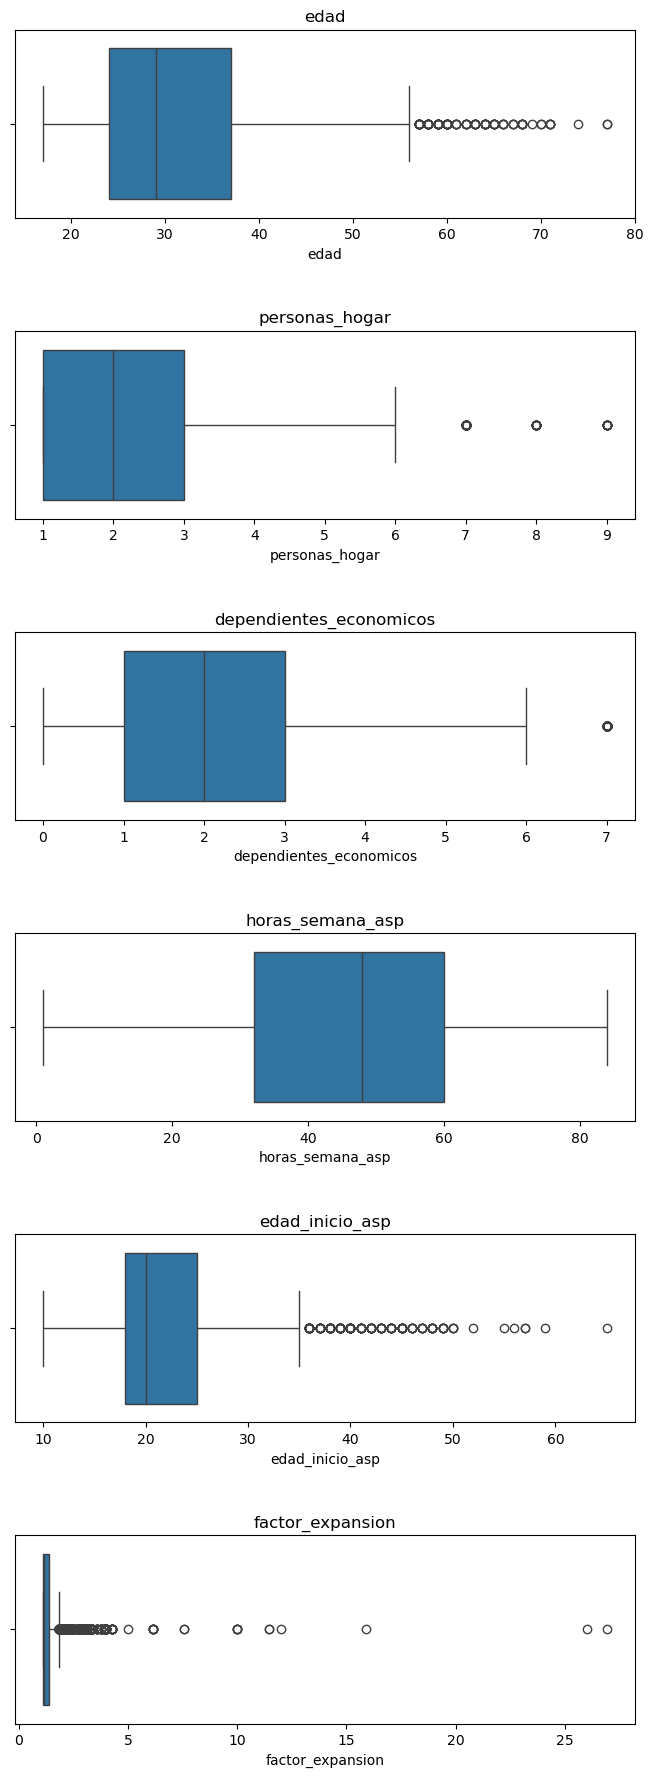

In [19]:
# Boxplots de las variables numéricas
cols_num = ['edad', 'personas_hogar', 'dependientes_economicos', 'horas_semana_asp', 'edad_inicio_asp', 'factor_expansion']

fig, ax = plt.subplots(nrows=len(cols_num), ncols=1, figsize=(8, 22))
fig.subplots_adjust(hspace=0.6)

for i, col in enumerate(cols_num):
    sns.boxplot(x=datos[col], ax=ax[i])
    ax[i].set_title(col)

plt.show()

In [20]:
print(datos[cols_num].describe())
print()
for col in cols_num:
    p1 = datos[col].quantile(0.01)
    p99 = datos[col].quantile(0.99)
    print(f'{col}: min={datos[col].min()}, p1%={p1}, p99%={p99}, max={datos[col].max()}')

              edad  personas_hogar  dependientes_economicos  horas_semana_asp  \
count  3004.000000     3004.000000              3004.000000       3004.000000   
mean     31.759654        2.452730                 2.159454         47.243342   
std      10.756136        1.581222                 1.707032         20.801114   
min      17.000000        1.000000                 0.000000          1.000000   
25%      24.000000        1.000000                 1.000000         32.000000   
50%      29.000000        2.000000                 2.000000         48.000000   
75%      37.000000        3.000000                 3.000000         60.000000   
max      77.000000        9.000000                 7.000000         84.000000   

       edad_inicio_asp  factor_expansion  
count      3004.000000       3004.000000  
mean         22.276298          1.468376  
std           7.049246          1.040931  
min          10.000000          1.111111  
25%          18.000000          1.125000  
50%         

In [21]:
# edad: la encuesta es de personas adultas; revisar quién tiene menos de 18
print("Registros con edad < 18:", (datos['edad'] < 18).sum())
datos[datos['edad'] < 18][['id_persona', 'edad', 'edad_inicio_asp']]

Registros con edad < 18: 1


,id_persona,edad,edad_inicio_asp
124,2083003,17,17


### Observaciones

- `personas_hogar` (máx. 9) y `dependientes_economicos` (máx. 7) no tienen valores atípicos: a diferencia de la base anterior (que llegaba a 41 personas), aquí no hace falta marcar nada.
- `horas_semana_asp` llega a 84, que es el máximo posible (12 horas × 7 días): se conserva.
- `edad_inicio_asp` va de 10 a 65 años. Los valores bajos son respuestas válidas de la encuesta (y un marcador de vulnerabilidad relevante), no errores de digitación: se conservan.
- `factor_expansion` llega a 26,9: es el ponderador muestral oficial, no se toca.
- **`edad`: hay 1 persona de 17 años** (`id_persona` 2083003). La población objeto del estudio es adulta (todas las demás tienen 18 o más), así que se **excluye** ese registro (3.004 → 3.003 filas). Si el grupo prefiere conservarlo, basta con omitir la celda siguiente.

In [22]:
# Excluir los registros con edad < 18
print(f'Tamaño antes: {datos.shape}')
datos = datos[datos['edad'] >= 18].copy()
print(f'Tamaño después: {datos.shape}')

Tamaño antes: (3004, 50)
Tamaño después: (3003, 50)


## Errores tipográficos / inconsistencias en variables categóricas


In [23]:
# Revisar unique() de cada columna categórica
for col in categoricas:
    print(f'{col}: {datos[col].unique().tolist()}')
    print()

localidad: ['ANTONIO NARIÑO', 'CHAPINERO', 'BOSA', 'USAQUEN', 'BARRIOS UNIDOS', 'CIUDAD BOLIVAR', 'SANTA FE', 'USME', 'TUNJUELITO', 'KENNEDY', 'FONTIBON', 'ENGATIVA', 'SUBA', 'TEUSAQUILLO', 'LOS MARTIRES', 'PUENTE ARANDA', 'LA CANDELARIA', 'RAFAEL URIBE', 'SAN CRISTOBAL']

sexo_nacimiento: ['Mujer', 'Hombre', 'Intersexual', 'No sabe/No responde']

orientacion_sexual: ['Bisexual', 'Heterosexual', 'Lesbiana', 'Gay', 'No sabe/No responde']

identidad_genero: ['Femenina', 'Persona no binaria', 'Masculina', 'Prefiere no decirlo', 'Transgénero', 'Otra']

estado_civil: ['Soltero(a)', 'Unión libre', 'Viudo(a)', 'Separado(a) de matrimonio', 'Separado(a) de unión libre', 'Casado(a)', 'Divorciado(a)']

autoreconocimiento_etnico: ['Ninguno', 'Afrocolombiano(a)/afrodescendiente', 'Indígena', 'Negro(a)', 'Gitano(a) (Rrom)', 'Raizal', 'Palenquero(a)']

pais_nacimiento: ['Colombia', 'Venezuela', 'No sabe / No responde', 'Argentina']

vive_permanente_bogota: ['No', 'Sí']

tiempo_viviendo_bogota: ['Meno

### Observaciones

- `localidad` viene en mayúsculas y sin tildes (`LOS MARTIRES`, `ENGATIVA`...): se pasa a su nombre normal con un diccionario (19 localidades).
- `pais_nacimiento` escribe `"No sabe / No responde"` con espacios, distinto del resto de la base: se unifica a `"No sabe/No responde"`. Además, hay 1 sola persona de Argentina (Colombia: 1.708, Venezuela: 1.290): se agrupa en `"Otro país"` para no tener una categoría de un solo caso.
- Las demás columnas ya quedaron consistentes al decodificarlas con la hoja *Valores*.

In [24]:
# Unificar localidades (mayúsculas sin tildes -> nombre normal)
localidades = {
    "ANTONIO NARIÑO": "Antonio Nariño", "BARRIOS UNIDOS": "Barrios Unidos", "BOSA": "Bosa",
    "CHAPINERO": "Chapinero", "CIUDAD BOLIVAR": "Ciudad Bolívar", "ENGATIVA": "Engativá",
    "FONTIBON": "Fontibón", "KENNEDY": "Kennedy", "LA CANDELARIA": "La Candelaria",
    "LOS MARTIRES": "Los Mártires", "PUENTE ARANDA": "Puente Aranda", "RAFAEL URIBE": "Rafael Uribe Uribe",
    "SAN CRISTOBAL": "San Cristóbal", "SANTA FE": "Santa Fe", "SUBA": "Suba",
    "TEUSAQUILLO": "Teusaquillo", "TUNJUELITO": "Tunjuelito", "USAQUEN": "Usaquén", "USME": "Usme",
}
datos['localidad'] = datos['localidad'].str.strip().map(localidades)

# pais_nacimiento: unificar 'No sabe / No responde' y agrupar el único caso de Argentina en 'Otro país'
datos['pais_nacimiento'] = datos['pais_nacimiento'].str.strip().replace({
    "No sabe / No responde": NSNR,
    "Argentina": "Otro país",
})

print(datos['localidad'].isna().sum(), "localidades sin traducir")
print(datos['localidad'].nunique(), "localidades")
print(datos['pais_nacimiento'].value_counts())

0 localidades sin traducir
19 localidades
pais_nacimiento
Colombia               1708
Venezuela              1290
No sabe/No responde       4
Otro país                 1
Name: count, dtype: int64


In [25]:
# Quitar espacios invisibles en todas las categóricas y comparar subniveles
for col in categoricas:
    datos[col] = datos[col].str.strip()
print("Subniveles totales tras strip:", sum(datos[c].nunique() for c in categoricas))

Subniveles totales tras strip: 190


## Consistencia lógica entre preguntas relacionadas


In [26]:
# Tabla cruzada: afiliado_seg_social_salud vs regimen_salud
print(pd.crosstab(datos['afiliado_seg_social_salud'], datos['regimen_salud']))

inconsistentes1 = datos[(datos['afiliado_seg_social_salud'] == 'No') & (datos['regimen_salud'] != NOAPLICA)]
print(f'Filas inconsistentes: {len(inconsistentes1)}')

regimen_salud              Contributivo (EPS)  \
afiliado_seg_social_salud                       
No                                          0   
No sabe/No responde                         0   
Sí                                        256   

regimen_salud              Especial (Fuerzas Armadas, Ecopetrol, universidades públicas)  \
afiliado_seg_social_salud                                                                  
No                                                                         0               
No sabe/No responde                                                        0               
Sí                                                                         2               

regimen_salud              No aplica (no se hizo la pregunta)  \
afiliado_seg_social_salud                                       
No                                                       1492   
No sabe/No responde                                        12   
Sí                               

In [27]:
# discriminacion_general vs discriminacion_personal_salud
# (solo se pregunta por personal de salud a quien dijo "Sí" a discriminación general)
print(pd.crosstab(datos['discriminacion_general'], datos['discriminacion_personal_salud']))

inconsistentes2 = datos[(datos['discriminacion_general'] != 'Sí') & (datos['discriminacion_personal_salud'] != NOAPLICA)]
print(f'Filas inconsistentes: {len(inconsistentes2)}')

discriminacion_personal_salud    No  No aplica (no se hizo la pregunta)  Sí
discriminacion_general                                                     
No                                0                                1775   0
No sabe/No responde               0                                  10   0
Sí                             1194                                   0  24
Filas inconsistentes: 0


In [28]:
# no_realiza_chequeos_preventivos vs barreras de acceso
# (las barreras solo se preguntan a quien NO hace chequeos preventivos)
barreras = ['barrera_falta_dinero', 'barrera_maltrato_institucional', 'barrera_negacion_servicio', 'barrera_acoso_sexual_consulta']
print(pd.crosstab(datos['no_realiza_chequeos_preventivos'], datos['barrera_falta_dinero']))

inconsistentes3 = datos[(datos['no_realiza_chequeos_preventivos'] == 'No') & (datos[barreras] != NOAPLICA).any(axis=1)]
print(f'Filas inconsistentes: {len(inconsistentes3)}')

barrera_falta_dinero              No  No aplica (no se hizo la pregunta)   Sí
no_realiza_chequeos_preventivos                                              
No                                 0                                2199    0
Sí                               537                                   0  267
Filas inconsistentes: 0


In [29]:
# edad vs edad_inicio_asp: nadie puede haber empezado después de su edad actual
inconsistentes4 = datos[datos['edad_inicio_asp'] > datos['edad']]
print(f'Filas inconsistentes: {len(inconsistentes4)}')

Filas inconsistentes: 0


### Conclusión del bloque

Las cuatro validaciones dan **0 filas inconsistentes**: las preguntas con salto se respetan (no afiliado → `regimen_salud` "No aplica"; sin discriminación general → `discriminacion_personal_salud` "No aplica"; hace chequeos → `barrera_*` "No aplica") y nadie empezó la actividad después de su edad actual.

## Tipos de datos finales


In [30]:
# Revisar dtypes
datos.dtypes

id_persona                           int64
factor_expansion                   float64
localidad                           object
edad                                 int64
sexo_nacimiento                     object
orientacion_sexual                  object
identidad_genero                    object
estado_civil                        object
autoreconocimiento_etnico           object
pais_nacimiento                     object
vive_permanente_bogota              object
tiempo_viviendo_bogota              object
victima_conflicto_armado            object
tipo_vivienda                       object
estrato                             object
tenencia_vivienda                   object
personas_hogar                       int64
dependientes_economicos              int64
autopercepcion_nivel_economico       int64
ingresos_suficientes_gastos         object
sabe_leer_escribir                  object
nivel_educativo                     object
actividad_principal                 object
horas_seman

In [31]:
# Convertir columnas categóricas a category
for col in categoricas:
    datos[col] = datos[col].astype('category')

datos.dtypes

id_persona                            int64
factor_expansion                    float64
localidad                          category
edad                                  int64
sexo_nacimiento                    category
orientacion_sexual                 category
identidad_genero                   category
estado_civil                       category
autoreconocimiento_etnico          category
pais_nacimiento                    category
vive_permanente_bogota             category
tiempo_viviendo_bogota             category
victima_conflicto_armado           category
tipo_vivienda                      category
estrato                            category
tenencia_vivienda                  category
personas_hogar                        int64
dependientes_economicos               int64
autopercepcion_nivel_economico        int64
ingresos_suficientes_gastos        category
sabe_leer_escribir                 category
nivel_educativo                    category
actividad_principal             

In [32]:
# Confirmar que las columnas numéricas queden como int/float
datos[numericas].dtypes

id_persona                          int64
edad                                int64
personas_hogar                      int64
dependientes_economicos             int64
autopercepcion_nivel_economico      int64
satisfaccion_actividad              int64
horas_semana_asp                    int64
edad_inicio_asp                     int64
factor_expansion                  float64
dtype: object

# Cierre


In [33]:
# Shape final y comparación con el original
print('Forma original: (3004, 51)')
print(f'Forma final: {datos.shape}')

Forma original: (3004, 51)
Forma final: (3003, 50)


### Resumen de la limpieza

- **Filas:** 3.004 → 3.003 (se excluyó 1 persona de 17 años). No había duplicados ni NaN.
- **Columnas:** 51 → 50 (se eliminó `resultado_encuesta`, sin variación).
- **Decodificación:** los códigos numéricos pasaron a texto usando la hoja *Valores* del Excel (99 → "No sabe/No responde"; "No Aplica" → "No aplica (no se hizo la pregunta)"). `forzada_relaciones_sexuales` traía el número de veces (0 = nunca): quedó como Sí / No / No sabe.
- **Estandarización:** localidades con nombre normal; `pais_nacimiento` unificado.
- **Sin tocar a propósito:** los "No aplica" y "No sabe/No responde" (decisión para la fase de modelado), y los valores extremos que son reales (`edad_inicio_asp`, `factor_expansion`).
- **Tipos:** categóricas a `category`; numéricas ya eran int/float.

In [34]:
# Guardar el dataset limpio (to_csv)
datos.to_csv('asp_2022_variables_limpio.csv', index=False, encoding='utf-8-sig')